# Modelagem preditiva — Risco de lesão em 14 dias (Série A 2022–2025)

Entregável de **Tópicos Especiais em ML**. Pergunta central: **dados públicos de partidas (minutos, calendário, histórico) permitem ordenar o risco de lesão, e a carga de minutos acrescenta algo além do histórico e do perfil?**

### Protocolo (definido antes de rodar)

**Amostra:** `dataset_modelo.csv`, amostra principal (`lesao_no_dia == 0`). Alvo `y` = lesão com início em (d, d+14].

**Cortes temporais** (a deriva de registro do tópico 4 da EDA obriga a separar regimes):
| Corte | Treino | Teste | Papel |
|---|---|---|---|
| A | 2022–23 | 2024 | protocolo original do artigo; treino e teste em regimes de registro diferentes |
| B | 2024 | 2025 | **principal**: registro comparável |
| C | 2022–24 | 2025 | todo o passado disponível |

**Hiperparâmetros:** busca em grade pequena com `StratifiedGroupKFold` (5 pastas, agrupado por jogador) **dentro do treino**, otimizando AUC-PR. Imputação e padronização ficam dentro do `Pipeline`.

**Métricas** (sem limiar primeiro): AUC-PR (AP) e lift sobre a prevalência; precision/recall/lift entre os **10% de maior risco** (política operacional, em vez de limiar de F1); AUC-ROC e Brier como complemento. IC 95% por **bootstrap por jogador** (500 sorteios, pareado entre modelos).

**Critério de sucesso (pré-definido):**
1. *Modelo útil:* no corte B, o limite inferior do IC 95% da AP fica acima da prevalência do teste **e** o lift@10% ≥ 1,5.
2. *A carga acrescenta sinal:* em pelo menos um dos cortes A/B, o IC 95% de ΔAP (modelo completo − modelo sem carga) exclui zero.

Se (2) falhar, a conclusão é que a carga pública não acrescenta informação além do histórico — também é um resultado.

## 1. Dados, atributos e cortes

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import GroupKFold, cross_val_predict

sys.path.append("../scripts")
import modelagem as M

PROC = Path("../data/processed")
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

bruto = pd.read_csv(PROC / "dataset_modelo.csv", parse_dates=["data"])
ds = bruto.loc[bruto["lesao_no_dia"].eq(0)].reset_index(drop=True)
X_all = M.preparar_atributos(ds)
y_all = ds["y"]

print("gradient boosting via:", "XGBoost" if M.TEM_XGB else "HistGradientBoosting (sklearn)")
print("atributos por grupo:", {g: len(c) for g, c in M.GRUPOS.items()}, "| total:", len(M.TODAS))

CORTES = {"A": ([2022, 2023], [2024]), "B": ([2024], [2025]), "C": ([2022, 2023, 2024], [2025])}

def separa(corte, base=ds, X=X_all, alvo="y"):
    tr_anos, te_anos = CORTES[corte]
    tr, te = base["ano"].isin(tr_anos), base["ano"].isin(te_anos)
    return X[tr], base.loc[tr, alvo], base.loc[tr, "player_id"], X[te], base.loc[te, alvo], base.loc[te, "player_id"]

resumo = []
for c in CORTES:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    resumo.append({"corte": c, "treino": f"{len(ytr):,}", "pos_treino": int(ytr.sum()), "prev_treino_%": round(100 * ytr.mean(), 2),
                   "teste": f"{len(yte):,}", "pos_teste": int(yte.sum()), "prev_teste_%": round(100 * yte.mean(), 2),
                   "jogadores_teste": gte.nunique(), "% teste já visto no treino": round(100 * gte.isin(set(gtr)).mean(), 1)})
display(pd.DataFrame(resumo).set_index("corte"))

gradient boosting via: XGBoost
atributos por grupo: {'perfil': 9, 'historico': 7, 'calendario': 3, 'carga': 6} | total: 25


,treino,pos_treino,prev_treino_%,teste,pos_teste,prev_teste_%,jogadores_teste,% teste já visto no treino
corte,,,,,,,,
A,"23,855",541,2.27,"11,928",828,6.94,709,71.9
B,"11,928",828,6.94,"11,921",998,8.37,736,67.2
C,"35,783",1369,3.83,"11,921",998,8.37,736,77.1


**Leitura:** os três cortes têm tamanhos e taxas bem diferentes. No **A**, o treino (2022–23) tem só 541 positivos e prevalência de 2,3%, e o teste (2024) tem 6,9%: a taxa triplica de um bloco para o outro por causa da deriva de registro. No **B**, treino e teste estão no mesmo regime (6,9% → 8,4%). O **C** junta todo o passado (1.369 positivos), misturando os dois regimes. Entre 67% e 77% das observações do teste são de jogadores que já aparecem no treino (o efeito disso é medido no 5.4).

## 2. Baselines

Antes de qualquer modelo: o que se consegue **sem aprendizado**?
- **Dummy (prior):** score constante → AP = prevalência.
- **Regra ACWR ≥ 1,5** (literatura clássica de carga).
- **Regra histórico:** ≥ 1 lesão nos últimos 12 meses.
- **Regra retorno:** ≤ 5 jogos desde a volta da última lesão.
- **Score de recência:** quanto mais recente a última lesão, maior o score (−dias desde a lesão).

In [2]:
def baselines(ds_te, X_te):
    return {
        "Dummy (prior)": np.full(len(ds_te), 0.5),
        "Regra ACWR>=1,5": (ds_te["acwr"].fillna(0) >= 1.5).astype(float).to_numpy(),
        "Regra lesão 12m": (ds_te["n_lesoes_12m"] >= 1).astype(float).to_numpy(),
        "Regra retorno<=5 jogos": (ds_te["jogos_desde_retorno"].fillna(999) <= 5).astype(float).to_numpy(),
        "Score recência lesão": -X_te["log_dias_desde_lesao"].to_numpy(),
    }

linhas = []
SCORES = {}  # SCORES[corte][modelo] = vetor de scores no teste
for c in CORTES:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    SCORES[c] = baselines(ds.loc[Xte.index], Xte)
    for nome, s in SCORES[c].items():
        linhas.append({"corte": c, "modelo": nome, **M.metricas(yte, s)})
tab_base = pd.DataFrame(linhas).set_index(["corte", "modelo"])
display(tab_base.drop(columns=["Brier"]).round(3))

AP  lift_AP  AUC_ROC  P@10%  R@10%  lift@10%  prevalencia
corte modelo                                                                              
A     Dummy (prior)           0.069    1.000    0.500  0.069  0.100     1.000        0.069
      Regra ACWR>=1,5         0.073    1.045    0.519  0.086  0.124     1.243        0.069
      Regra lesão 12m         0.078    1.127    0.556  0.085  0.123     1.229        0.069
      Regra retorno<=5 jogos  0.077    1.107    0.539  0.102  0.147     1.473        0.069
      Score recência lesão    0.095    1.364    0.588  0.123  0.177     1.772        0.069
B     Dummy (prior)           0.084    1.000    0.500  0.084  0.100     1.000        0.084
      Regra ACWR>=1,5         0.085    1.020    0.510  0.093  0.111     1.109        0.084
      Regra lesão 12m         0.098    1.171    0.575  0.104  0.124     1.238        0.084
      Regra retorno<=5 jogos  0.094    1.122    0.546  0.120  0.143     1.430        0.084
      Score recência lesão    0.117    1.393    0.604  0.121  0.145     1.447        0.084
C     Dummy (prior)           0.084    1.000    0.500  0.084  0.100     1.000        0.084
      Regra ACWR>=1,5         0.085    1.020    0.510  0.093  0.111     1.109        0.084
      Regra lesão 12m         0.098    1.171    0.575  0.104  0.124     1.238        0.084
      Regra retorno<=5 jogos  0.094    1.122    0.546  0.120  0.143     1.430        0.084
      Score recência lesão    0.117    1.393    0.604  0.121  0.145     1.447        0.084

**Leitura:** o Dummy confirma a escala (AP = prevalência, lift = 1). A **regra clássica de carga (ACWR ≥ 1,5) fica no nível do acaso** em todos os cortes (lift da AP de 1,02–1,05). As regras de histórico funcionam melhor, e o **score de recência da última lesão** é o baseline mais forte (AP 0,095 no corte A e 0,117 no B, ou 1,36–1,39× o acaso). Essa é a régua que os modelos precisam superar.

## 3. Modelos

Regressão logística (baseline linear), Random Forest, Gradient Boosting e MLP pequeno, ajustados em cada corte. O MLP é treinado com 10 sementes; reportamos a média ± desvio da AP entre sementes e usamos a média das previsões nas demais métricas.

In [3]:
import time, warnings
warnings.filterwarnings("ignore", category=UserWarning)

MELHORES = {}   # MELHORES[corte][modelo] = estimador ajustado
PARAMS = {}
mlp_sementes = {}
linhas = []
for c in CORTES:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    modelos = M.fabrica_modelos(n_neg_por_pos=(1 - ytr.mean()) / ytr.mean())
    MELHORES[c], PARAMS[c] = {}, {}
    for nome, (pipe, grade) in modelos.items():
        t0 = time.time()
        busca = M.ajustar(pipe, grade, Xtr, ytr, gtr)
        PARAMS[c][nome] = {k.replace("clf__", ""): v for k, v in busca.best_params_.items()}
        if nome == "MLP":
            # 10 sementes com o melhor alpha; score final = média das previsões
            aps, prevs = [], []
            for s in range(10):
                est = clone(busca.best_estimator_).set_params(clf__random_state=s).fit(Xtr, ytr)
                p = est.predict_proba(Xte)[:, 1]
                prevs.append(p); aps.append(average_precision_score(yte, p))
            mlp_sementes[c] = (np.mean(aps), np.std(aps))
            score = np.mean(prevs, axis=0)
            MELHORES[c][nome] = est
        else:
            MELHORES[c][nome] = busca.best_estimator_
            score = busca.best_estimator_.predict_proba(Xte)[:, 1]
        SCORES[c][nome] = score
        linhas.append({"corte": c, "modelo": nome, "AP_cv_treino": busca.best_score_, **M.metricas(yte, score)})
        print(f"[{c}] {nome:20s} AP_cv={busca.best_score_:.3f} AP_teste={linhas[-1]['AP']:.3f}  ({time.time() - t0:.0f}s)  {PARAMS[c][nome]}")

tab_mod = pd.DataFrame(linhas).set_index(["corte", "modelo"])
display(tab_mod.round(3))
print("MLP — AP no teste entre 10 sementes (média ± dp):", {c: f"{m:.3f} ± {s:.3f}" for c, (m, s) in mlp_sementes.items()})

[A] Regressao logistica  AP_cv=0.044 AP_teste=0.118  (15s)  {'C': 0.01, 'class_weight': None}


[A] Random Forest        AP_cv=0.039 AP_teste=0.108  (82s)  {'max_features': 'sqrt', 'min_samples_leaf': 100}


[A] XGBoost              AP_cv=0.038 AP_teste=0.111  (19s)  {'max_depth': 2, 'min_child_weight': 20, 'scale_pos_weight': 1.0}


[A] MLP                  AP_cv=0.027 AP_teste=0.067  (21s)  {'alpha': 0.1}


[B] Regressao logistica  AP_cv=0.121 AP_teste=0.140  (2s)  {'C': 1.0, 'class_weight': 'balanced'}


[B] Random Forest        AP_cv=0.112 AP_teste=0.126  (48s)  {'max_features': 0.5, 'min_samples_leaf': 100}


... (4 outputs left out)

[C] XGBoost              AP_cv=0.079 AP_teste=0.130  (24s)  {'max_depth': 2, 'min_child_weight': 5, 'scale_pos_weight': 1.0}


[C] MLP                  AP_cv=0.048 AP_teste=0.109  (36s)  {'alpha': 0.001}


AP_cv_treino     AP  lift_AP  AUC_ROC  P@10%  R@10%  lift@10%  Brier  prevalencia
corte modelo                                                                                                
A     Regressao logistica         0.044  0.118    1.696    0.639  0.149  0.215     2.149  0.065        0.069
      Random Forest               0.039  0.108    1.554    0.618  0.131  0.188     1.884  0.191        0.069
      XGBoost                     0.038  0.111    1.597    0.620  0.148  0.213     2.125  0.065        0.069
      MLP                         0.027  0.067    0.970    0.501  0.062  0.089     0.894  0.066        0.069
B     Regressao logistica         0.121  0.140    1.668    0.646  0.170  0.203     2.034  0.238        0.084
      Random Forest               0.112  0.126    1.511    0.639  0.148  0.176     1.764  0.198        0.084
      XGBoost                     0.109  0.127    1.512    0.633  0.150  0.179     1.794  0.076        0.084
      MLP                         0.076  0.098    1.174    0.557  0.109  0.130     1.303  0.078        0.084
C     Regressao logistica         0.088  0.139    1.654    0.652  0.168  0.200     2.004  0.283        0.084
      Random Forest               0.077  0.127    1.517    0.630  0.155  0.185     1.854  0.228        0.084
      XGBoost                     0.079  0.130    1.551    0.645  0.153  0.182     1.824  0.076        0.084
      MLP                         0.048  0.109    1.305    0.606  0.117  0.140     1.403  0.077        0.084

MLP — AP no teste entre 10 sementes (média ± dp): {'A': '0.070 ± 0.008', 'B': '0.093 ± 0.006', 'C': '0.105 ± 0.003'}


**Leitura:** a **regressão logística é o melhor modelo nos três cortes** (AP 0,118 / 0,140 / 0,139), à frente de XGBoost (0,111 / 0,127 / 0,130) e Random Forest (0,108 / 0,126 / 0,127). O **MLP fica por último**: no corte A ele nem supera o acaso (AP 0,067 contra prevalência 0,069) e no B chega a 0,098, com variação pequena entre sementes (dp 0,003–0,008). A busca escolheu sempre os modelos mais simples da grade (árvores de profundidade 2, folhas de 100 observações), sinal de que há pouca estrutura não linear para aprender com ~270–1.370 episódios. Treinar com todo o passado (C) não melhora em relação a treinar só em 2024 (B): dados do regime antigo de registro não acrescentam. A AP na validação do treino é menor que no teste por causa da prevalência menor no treino, não por sobreajuste.

### 3.1 Intervalos de confiança (bootstrap por jogador)

AP e precisão entre os 10% de maior risco, com IC 95%. Os mesmos sorteios valem para todos os modelos de um corte.

AP         AP_IC95      P@10%_IC95  prevalencia  IC_AP_acima_prev
corte modelo                                                                                      
A     Dummy (prior)           0.069  [0.062, 0.078]  [0.062, 0.078]        0.069             False
      Regra ACWR>=1,5         0.073  [0.065, 0.082]  [0.070, 0.103]        0.069             False
      Regra lesão 12m         0.078  [0.069, 0.089]  [0.074, 0.098]        0.069             False
      Regra retorno<=5 jogos  0.077  [0.068, 0.089]  [0.084, 0.125]        0.069             False
      Score recência lesão    0.095  [0.080, 0.114]  [0.097, 0.153]        0.069              True
      Regressao logistica     0.118  [0.098, 0.141]  [0.122, 0.181]        0.069              True
      Random Forest           0.108  [0.092, 0.129]  [0.103, 0.160]        0.069              True
      XGBoost                 0.111  [0.094, 0.133]  [0.121, 0.181]        0.069              True
      MLP                     0.067  [0.060, 0.078]  [0.043, 0.078]        0.069             False
B     Dummy (prior)           0.084  [0.075, 0.092]  [0.075, 0.092]        0.084             False
      Regra ACWR>=1,5         0.085  [0.077, 0.095]  [0.079, 0.108]        0.084             False
      Regra lesão 12m         0.098  [0.087, 0.110]  [0.091, 0.116]        0.084              True
      Regra retorno<=5 jogos  0.094  [0.083, 0.105]  [0.099, 0.139]        0.084             False
      Score recência lesão    0.117  [0.099, 0.138]  [0.090, 0.154]        0.084              True
      Regressao logistica     0.140  [0.119, 0.169]  [0.134, 0.209]        0.084              True
      Random Forest           0.126  [0.110, 0.148]  [0.120, 0.186]        0.084              True
      XGBoost                 0.127  [0.109, 0.152]  [0.118, 0.186]        0.084              True
      MLP                     0.098  [0.087, 0.114]  [0.088, 0.138]        0.084              True
C     Dummy (prior)           0.084  [0.075, 0.092]  [0.075, 0.092]        0.084             False
      Regra ACWR>=1,5         0.085  [0.077, 0.095]  [0.079, 0.108]        0.084             False
      Regra lesão 12m         0.098  [0.087, 0.110]  [0.091, 0.116]        0.084              True
      Regra retorno<=5 jogos  0.094  [0.083, 0.105]  [0.099, 0.139]        0.084             False
      Score recência lesão    0.117  [0.099, 0.138]  [0.090, 0.154]        0.084              True
      Regressao logistica     0.139  [0.118, 0.168]  [0.129, 0.203]        0.084              True
      Random Forest           0.127  [0.110, 0.150]  [0.120, 0.190]        0.084              True
      XGBoost                 0.130  [0.112, 0.154]  [0.121, 0.187]        0.084              True
      MLP                     0.109  [0.096, 0.127]  [0.096, 0.149]        0.084              True

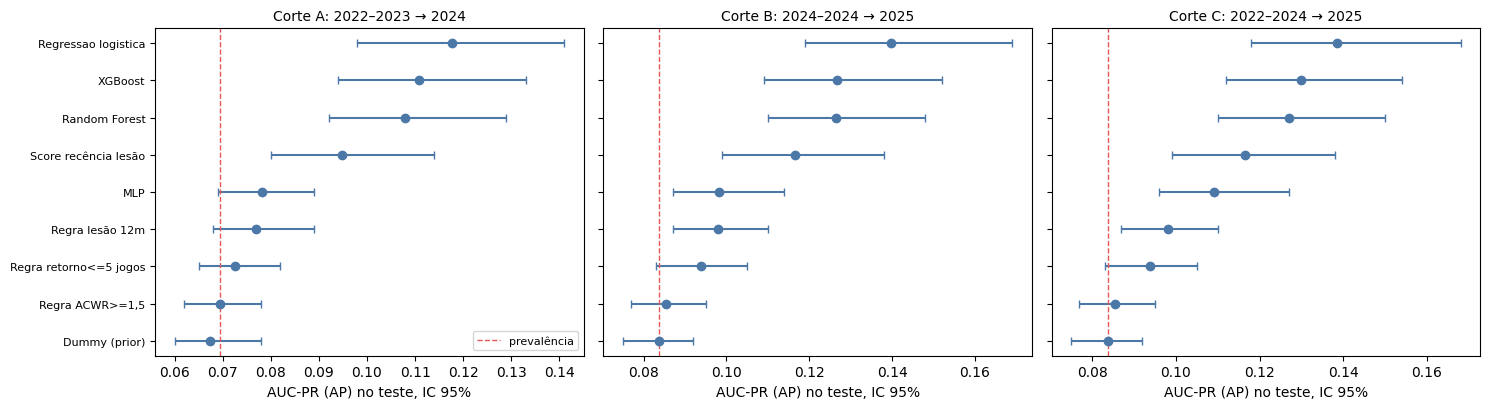

In [4]:
BOOT = {}
linhas = []
for c in CORTES:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    BOOT[c] = M.bootstrap_jogador(yte, SCORES[c], gte, n_boot=500)
    for nome, b in BOOT[c].items():
        lo, hi = M.ic(b["AP"]); plo, phi = M.ic(b["Pk"])
        linhas.append({"corte": c, "modelo": nome, "AP": average_precision_score(yte, SCORES[c][nome]),
                       "AP_IC95": f"[{lo:.3f}, {hi:.3f}]", "P@10%_IC95": f"[{plo:.3f}, {phi:.3f}]",
                       "prevalencia": yte.mean(), "IC_AP_acima_prev": lo > yte.mean()})
tab_ic = pd.DataFrame(linhas).set_index(["corte", "modelo"])
display(tab_ic.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, c in zip(axes, CORTES):
    t = tab_ic.loc[c].sort_values("AP")
    lo = [float(s.strip("[]").split(",")[0]) for s in t["AP_IC95"]]
    hi = [float(s.strip("[]").split(",")[1]) for s in t["AP_IC95"]]
    ax.errorbar(t["AP"], range(len(t)), xerr=[t["AP"] - lo, np.array(hi) - t["AP"]], fmt="o", color="#4C78A8", capsize=3)
    ax.axvline(t["prevalencia"].iloc[0], color="#E45756", ls="--", lw=1, label="prevalência")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8)
    ax.set_title(f"Corte {c}: {CORTES[c][0][0]}–{CORTES[c][0][-1]} → {CORTES[c][1][0]}", fontsize=10)
    ax.set_xlabel("AUC-PR (AP) no teste, IC 95%")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "m01_ap_ic_por_corte.png", dpi=120)
plt.show()

**Leitura:** nos cortes B e C, **todos os modelos têm o IC 95% da AP acima da prevalência**; no A, todos menos o MLP. O sinal é real e não depende da amostra. Os intervalos de regressão logística, XGBoost e Random Forest **se sobrepõem**, então não dá para afirmar que um é melhor que o outro. Dá para afirmar que o modelo mais simples basta. A precisão entre os 10% de maior risco da regressão logística no corte B fica entre 13,4% e 20,9%, contra 8,4% do acaso.

### 3.2 Curvas precisão–recall e lift por decil (corte B)

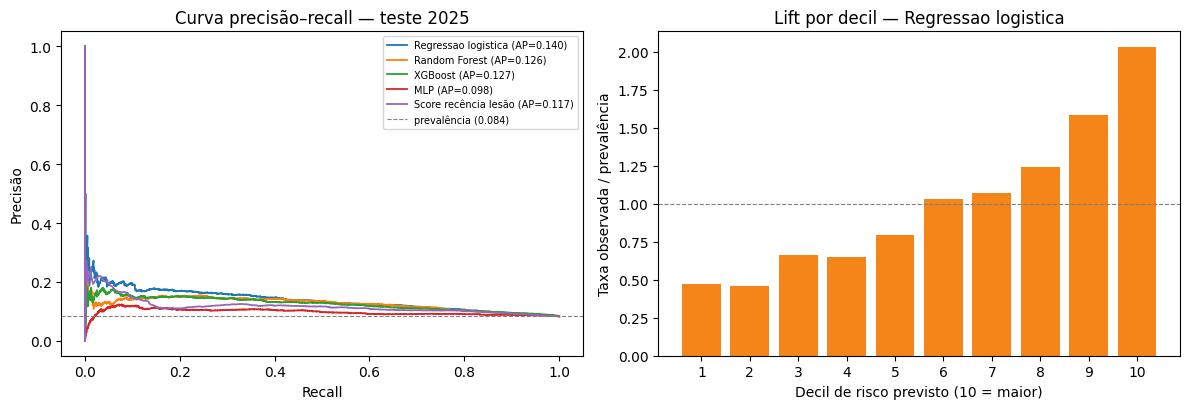

Melhor modelo no corte B (AP pontual): Regressao logistica
Lift por decil: {1: 0.47, 2: 0.46, 3: 0.66, 4: 0.65, 5: 0.79, 6: 1.03, 7: 1.07, 8: 1.24, 9: 1.58, 10: 2.03}


In [5]:
c = "B"
Xtr, ytr, gtr, Xte, yte, gte = separa(c)
modelos_plot = ["Regressao logistica", "Random Forest", [m for m in SCORES[c] if "Boost" in m][0], "MLP", "Score recência lesão"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for nome in modelos_plot:
    pr, rc, _ = precision_recall_curve(yte, SCORES[c][nome])
    axes[0].plot(rc, pr, label=f"{nome} (AP={average_precision_score(yte, SCORES[c][nome]):.3f})", lw=1.3)
axes[0].axhline(yte.mean(), color="gray", ls="--", lw=0.8, label=f"prevalência ({yte.mean():.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precisão"); axes[0].set_title("Curva precisão–recall — teste 2025")
axes[0].legend(fontsize=7)

melhor_B = tab_mod.loc["B", "AP"].idxmax()
dec = pd.qcut(pd.Series(SCORES[c][melhor_B]).rank(method="first"), 10, labels=range(1, 11))
lift = pd.Series(yte.to_numpy()).groupby(dec.to_numpy()).mean() / yte.mean()
axes[1].bar(lift.index.astype(str), lift.values, color="#F58518")
axes[1].axhline(1, color="gray", ls="--", lw=0.8)
axes[1].set_xlabel("Decil de risco previsto (10 = maior)"); axes[1].set_ylabel("Taxa observada / prevalência")
axes[1].set_title(f"Lift por decil — {melhor_B}")
fig.tight_layout()
fig.savefig(FIG / "m02_pr_e_lift_corte_B.png", dpi=120)
plt.show()
print("Melhor modelo no corte B (AP pontual):", melhor_B)
print("Lift por decil:", lift.round(2).to_dict())

**Leitura:** a curva precisão–recall mostra o padrão típico de sinal modesto: precisão de 20–35% só para os pouquíssimos casos de score mais alto, caindo logo para ~15–18% e se aproximando da prevalência à medida que o recall cresce. O **lift por decil** é a leitura mais útil para a prática. O décimo de maior risco tem **2,03×** a taxa média, os dois de menor risco têm **0,47×**, e o crescimento entre eles é quase monotônico. Entre o topo e a base da lista, a diferença de risco é de ~4 vezes.

## 4. Ablação por grupo de atributos — a carga acrescenta sinal?

Mesmos hiperparâmetros do modelo completo de cada corte, variando só os atributos. Comparamos com Gradient Boosting e com a regressão logística. ΔAP com IC 95% pareado (mesmos sorteios de jogadores).

In [6]:
GB = [m for m in MELHORES["A"] if "Boost" in m][0]
CONJUNTOS = {
    "perfil": ["perfil"],
    "perfil+histórico": ["perfil", "historico"],
    "perfil+hist+calendário (sem carga)": ["perfil", "historico", "calendario"],
    "completo": ["perfil", "historico", "calendario", "carga"],
    "só carga": ["carga"],
    "só calendário+carga": ["calendario", "carga"],
}
ABL = {}
linhas = []
for c in ["A", "B", "C"]:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    ABL[c] = {}
    for modelo in [GB, "Regressao logistica"]:
        for nome, grupos in CONJUNTOS.items():
            cols = [col for g in grupos for col in M.GRUPOS[g]]
            est = clone(MELHORES[c][modelo]).fit(Xtr[cols], ytr)
            ABL[c][(modelo, nome)] = est.predict_proba(Xte[cols])[:, 1]
    boot = M.bootstrap_jogador(yte, {f"{m}|{n}": s for (m, n), s in ABL[c].items()}, gte, n_boot=500)
    for (modelo, nome), s in ABL[c].items():
        b = boot[f"{modelo}|{nome}"]["AP"]
        lo, hi = M.ic(b)
        linha = {"corte": c, "modelo": modelo, "atributos": nome, "AP": average_precision_score(yte, s), "AP_IC95": f"[{lo:.3f}, {hi:.3f}]",
                 "lift@10%": M.metricas(yte, s)["lift@10%"]}
        if nome == "completo":
            d = b - boot[f"{modelo}|perfil+hist+calendário (sem carga)"]["AP"]
            dlo, dhi = M.ic(d)
            linha["ΔAP carga (IC95)"] = f"{np.mean(d):+.4f} [{dlo:+.4f}, {dhi:+.4f}]"
            linha["carga_significativa"] = (dlo > 0) or (dhi < 0)
        linhas.append(linha)
tab_abl = pd.DataFrame(linhas).set_index(["corte", "modelo", "atributos"])
display(tab_abl.round(3))

AP         AP_IC95  lift@10%            ΔAP carga (IC95) carga_significativa
corte modelo              atributos                                                                                                          
A     XGBoost             perfil                              0.073  [0.063, 0.086]     0.872                         NaN                 NaN
                          perfil+histórico                    0.096  [0.084, 0.114]     1.775                         NaN                 NaN
                          perfil+hist+calendário (sem carga)  0.110  [0.095, 0.130]     2.113                         NaN                 NaN
                          completo                            0.111  [0.094, 0.133]     2.125  +0.0006 [-0.0048, +0.0064]               False
                          só carga                            0.073  [0.065, 0.086]     1.111                         NaN                 NaN
                          só calendário+carga                 0.083  [0.073, 0.098]     1.365                         NaN                 NaN
      Regressao logistica perfil                              0.077  [0.067, 0.093]     0.983                         NaN                 NaN
                          perfil+histórico                    0.101  [0.086, 0.119]     1.763                         NaN                 NaN
                          perfil+hist+calendário (sem carga)  0.116  [0.098, 0.138]     2.161                         NaN                 NaN
                          completo                            0.118  [0.098, 0.141]     2.149  +0.0017 [-0.0003, +0.0039]               False
                          só carga                            0.075  [0.064, 0.091]     1.135                         NaN                 NaN
                          só calendário+carga                 0.091  [0.079, 0.106]     1.437                         NaN                 NaN
B     XGBoost             perfil                              0.102  [0.087, 0.119]     1.380                         NaN                 NaN
                          perfil+histórico                    0.104  [0.089, 0.120]     1.283                         NaN                 NaN
                          perfil+hist+calendário (sem carga)  0.121  [0.105, 0.143]     1.673                         NaN                 NaN
                          completo                            0.127  [0.109, 0.152]     1.794  +0.0057 [+0.0006, +0.0119]                True
                          só carga                            0.087  [0.077, 0.099]     1.102                         NaN                 NaN
                          só calendário+carga                 0.106  [0.093, 0.121]     1.473                         NaN                 NaN
      Regressao logistica perfil                              0.103  [0.089, 0.122]     1.425                         NaN                 NaN
                          perfil+histórico                    0.131  [0.108, 0.160]     1.844                         NaN                 NaN
                          perfil+hist+calendário (sem carga)  0.139  [0.118, 0.169]     2.074                         NaN                 NaN
                          completo                            0.140  [0.119, 0.169]     2.034  +0.0004 [-0.0036, +0.0043]               False
                          só carga                            0.089  [0.080, 0.100]     1.072                         NaN                 NaN
                          só calendário+carga                 0.104  [0.092, 0.119]     1.313                         NaN                 NaN
C     XGBoost             perfil                              0.089  [0.078, 0.105]     1.051                         NaN                 NaN
                          perfil+histórico                    0.116  [0.100, 0.142]     1.543                         NaN                 NaN
                          perfil+hist+calendário (sem carga)  0.131  [0.113, 0.155]     1

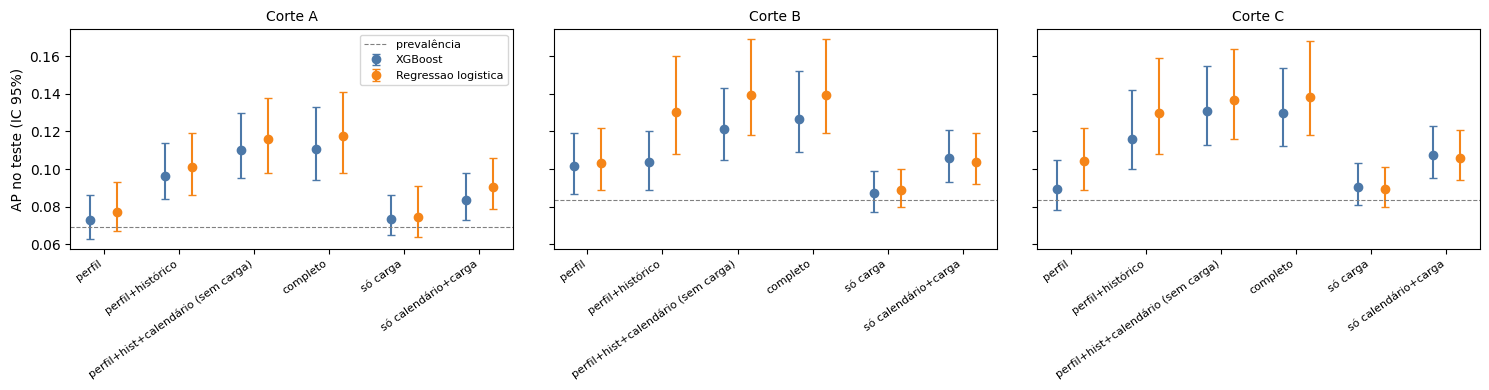

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
ordem = list(CONJUNTOS)
for ax, c in zip(axes, ["A", "B", "C"]):
    yte = separa(c)[4]
    for modelo, cor, desloc in [(GB, "#4C78A8", -0.18), ("Regressao logistica", "#F58518", 0.18)]:
        t = tab_abl.loc[(c, modelo)].loc[ordem]
        lo = [float(s.strip("[]").split(",")[0]) for s in t["AP_IC95"]]
        hi = [float(s.strip("[]").split(",")[1]) for s in t["AP_IC95"]]
        ax.errorbar(np.arange(len(t)) + desloc, t["AP"], yerr=[t["AP"] - lo, np.array(hi) - t["AP"]], fmt="o",
                    color=cor, capsize=3, label=modelo)
    ax.axhline(yte.mean(), color="gray", ls="--", lw=0.8, label="prevalência")
    ax.set_xticks(range(len(ordem))); ax.set_xticklabels(ordem, rotation=35, ha="right", fontsize=8)
    ax.set_title(f"Corte {c}", fontsize=10)
axes[0].set_ylabel("AP no teste (IC 95%)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "m03_ablacao.png", dpi=120)
plt.show()

**Leitura:** a ablação responde à pergunta central.
- **Perfil** sozinho (idade, posição, titular) fica perto do acaso (AP 0,073–0,104).
- **Histórico** dá o maior salto (ex.: regressão logística no corte B, de 0,103 para 0,131).
- **Calendário** acrescenta mais um degrau (+0,007 a +0,017), puxado pelos jogos do clube nos próximos 14 dias.
- **Carga** acrescenta praticamente nada: ΔAP entre −0,001 e +0,006. **Só carga** fica no nível do acaso (lift da AP de 1,0–1,1), e **calendário + carga** (0,083–0,107) fica bem abaixo de qualquer conjunto com histórico.

Pelo critério definido antes de rodar, o **critério 2 é atendido**: no corte B com XGBoost, ΔAP = +0,0057 [+0,0006; +0,0119]. Mas o sinal é **frágil**: aparece em 1 das 4 comparações pré-definidas (sem correção para comparações múltiplas), é pequeno (~5% relativo), some no corte C (−0,0007) e não aparece na regressão logística (+0,0004). Além disso, o XGBoost com carga (0,127) fica abaixo da regressão logística sem carga (0,139). Conclusão: **a carga de minutos acrescenta, no máximo, um sinal marginal e instável**; o desempenho vem do histórico e do calendário.

## 5. Robustez

- **5.1 Origem móvel 2022 → 2023** (os dois anos de registro pobre).
- **5.2 Alvo incluindo o dia do jogo** (`y_com_dia`, janela [d, d+14], com as linhas de lesão no dia).
- **5.3 Clubes deixados de fora:** validação cruzada em 2024–25 agrupando por clube × agrupando por jogador.
- **5.4 Jogadores vistos × não vistos** no treino (corte B).
- **5.5 Estratégias de desbalanceamento** (corte B, Gradient Boosting).

In [8]:
linhas = []
# 5.1 origem móvel 2022 -> 2023
CORTES["2022→2023"] = ([2022], [2023])
Xtr, ytr, gtr, Xte, yte, gte = separa("2022→2023")
for modelo in [GB, "Regressao logistica"]:
    s = clone(MELHORES["A"][modelo]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    linhas.append({"teste": "5.1 origem 2022→2023", "modelo": modelo, **M.metricas(yte, s)})

# 5.2 alvo com o dia do jogo (todas as linhas do arquivo)
X_b = M.preparar_atributos(bruto)
Xtr, ytr, gtr, Xte, yte, gte = separa("B", base=bruto, X=X_b, alvo="y_com_dia")
for modelo in [GB, "Regressao logistica"]:
    s = clone(MELHORES["B"][modelo]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    linhas.append({"teste": "5.2 alvo [d, d+14] (corte B)", "modelo": modelo, **M.metricas(yte, s)})
del CORTES["2022→2023"]
tab_rob = pd.DataFrame(linhas).set_index(["teste", "modelo"])
display(tab_rob.drop(columns=["Brier"]).round(3))
print("Referência corte B (alvo principal):")
display(tab_mod.loc[[("B", GB), ("B", "Regressao logistica")]].drop(columns=["Brier", "AP_cv_treino"]).round(3))

AP  lift_AP  AUC_ROC  P@10%  R@10%  lift@10%  prevalencia
teste                        modelo                                                                           
5.1 origem 2022→2023         XGBoost              0.028    1.448    0.602  0.034  0.172     1.716         0.02
                             Regressao logistica  0.030    1.557    0.610  0.034  0.176     1.759         0.02
5.2 alvo [d, d+14] (corte B) XGBoost              0.133    1.490    0.630  0.162  0.181     1.806         0.09
                             Regressao logistica  0.147    1.644    0.644  0.179  0.200     2.001         0.09

Referência corte B (alvo principal):


AP  lift_AP  AUC_ROC  P@10%  R@10%  lift@10%  prevalencia
corte modelo                                                                           
B     XGBoost              0.127    1.512    0.633   0.15  0.179     1.794        0.084
      Regressao logistica  0.140    1.668    0.646   0.17  0.203     2.034        0.084

**Leitura:**
- **5.1** No regime de registro pobre (2022 → 2023, prevalência de 2,0%), os modelos ainda têm AP 1,45–1,56× o acaso e lift@10% de ~1,7. O sinal **não é um artefato** dos anos de registro mais completo.
- **5.2** Com o alvo que inclui lesões no dia do jogo (`y_com_dia`), os resultados praticamente não mudam (regressão logística: AP 0,147 e lift 1,64, contra 0,140 e 1,67 no alvo principal). A escolha de excluir essas 168 linhas não afeta as conclusões.

In [9]:
# 5.3 clubes deixados de fora × jogadores deixados de fora (2024–25 juntos, CV de 5 pastas)
m = ds["ano"].isin([2024, 2025])
X2, y2 = X_all[m], y_all[m]
linhas = []
for agrupar_por in ["player_id", "clube_id"]:
    grupos = ds.loc[m, agrupar_por]
    for modelo in [GB, "Regressao logistica"]:
        oof = cross_val_predict(clone(MELHORES["B"][modelo]), X2, y2, groups=grupos, cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
        # AP calculada dentro de cada ano e promediada (evita misturar prevalências)
        aps = [average_precision_score(y2[ds.loc[m, "ano"] == a], oof[(ds.loc[m, "ano"] == a).to_numpy()]) for a in (2024, 2025)]
        linhas.append({"agrupamento": agrupar_por, "modelo": modelo, "AP_2024": aps[0], "AP_2025": aps[1]})
display(pd.DataFrame(linhas).set_index(["agrupamento", "modelo"]).round(3))

# 5.4 jogadores vistos × não vistos (corte B)
Xtr, ytr, gtr, Xte, yte, gte = separa("B")
visto = gte.isin(set(gtr)).to_numpy()
linhas = []
for nome in [GB, "Regressao logistica"]:
    for rot, msk in [("visto no treino", visto), ("novo", ~visto)]:
        linhas.append({"modelo": nome, "grupo": rot, "n": int(msk.sum()), "prev": yte[msk].mean(),
                       "AP": average_precision_score(yte[msk], SCORES["B"][nome][msk]),
                       "lift_AP": average_precision_score(yte[msk], SCORES["B"][nome][msk]) / yte[msk].mean()})
display(pd.DataFrame(linhas).set_index(["modelo", "grupo"]).round(3))

AP_2024  AP_2025
agrupamento modelo                               
player_id   XGBoost                0.109    0.134
            Regressao logistica    0.120    0.143
clube_id    XGBoost                0.111    0.132
            Regressao logistica    0.124    0.139

n   prev     AP  lift_AP
modelo              grupo                                       
XGBoost             visto no treino  8008  0.085  0.128    1.505
                    novo             3913  0.082  0.127    1.561
Regressao logistica visto no treino  8008  0.085  0.139    1.643
                    novo             3913  0.082  0.147    1.809

**Leitura:**
- **5.3** Deixar **clubes inteiros** fora do treino dá a mesma AP que deixar jogadores de fora (regressão logística 0,124 / 0,139 contra 0,120 / 0,143 em 2024 / 2025). O modelo **generaliza para clubes que não viu**, como se esperava ao excluir o clube dos atributos.
- **5.4** Para jogadores **novos** (que não aparecem no treino), a AP é igual ou até um pouco maior que para os já vistos (0,147 contra 0,139 na regressão logística). O modelo não está memorizando jogadores.

In [10]:
# 5.5 desbalanceamento (corte B, Gradient Boosting): sem peso, peso sqrt, peso n0/n1, undersampling 1:5
Xtr, ytr, gtr, Xte, yte, gte = separa("B")
razao = (1 - ytr.mean()) / ytr.mean()
base_gb = clone(MELHORES["B"][GB])
param_peso = "clf__scale_pos_weight" if M.TEM_XGB else "clf__class_weight"
def peso(w):
    return w if M.TEM_XGB else ({0: 1.0, 1: w} if w != 1 else None)
linhas = []
for rot, w in [("sem peso", 1.0), ("peso √(n0/n1)", float(np.sqrt(razao))), ("peso n0/n1", float(razao))]:
    s = clone(base_gb).set_params(**{param_peso: peso(w)}).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    linhas.append({"estratégia": rot, **M.metricas(yte, s), "média do score": s.mean()})
rng = np.random.default_rng(M.SEMENTE)
neg = np.flatnonzero(ytr.to_numpy() == 0); pos_ = np.flatnonzero(ytr.to_numpy() == 1)
sub = np.concatenate([pos_, rng.choice(neg, size=5 * len(pos_), replace=False)])
s = clone(base_gb).set_params(**{param_peso: peso(1.0)}).fit(Xtr.iloc[sub], ytr.iloc[sub]).predict_proba(Xte)[:, 1]
linhas.append({"estratégia": "undersampling 1:5 (só treino)", **M.metricas(yte, s), "média do score": s.mean()})
tab_desb = pd.DataFrame(linhas).set_index("estratégia")
display(tab_desb.round(4))
print(f"prevalência real no teste: {yte.mean():.4f}")

,AP,lift_AP,AUC_ROC,P@10%,R@10%,lift@10%,Brier,prevalencia,média do score
estratégia,,,,,,,,,
sem peso,0.1266,1.5121,0.6333,0.1502,0.1794,1.7937,0.0757,0.0837,0.0742
peso √(n0/n1),0.1269,1.5155,0.6334,0.1628,0.1944,1.9441,0.0964,0.0837,0.2102
peso n0/n1,0.1256,1.5003,0.6325,0.1560,0.1864,1.8639,0.2256,0.0837,0.4489
undersampling 1:5 (só treino),0.1271,1.5177,0.6332,0.1602,0.1914,1.9140,0.0866,0.0837,0.1712


prevalência real no teste: 0.0837


**Leitura:** as quatro estratégias dão **a mesma AP** (0,126–0,127) e lift parecido. Os pesos de classe só deslocam a escala dos scores (média de 0,074 sem peso para 0,449 com peso n0/n1) e **pioram a calibração** (Brier de 0,076 para 0,226). O undersampling também não ajuda. Para ordenar risco, o desbalanceamento não precisa de tratamento. Isso confirma a decisão de não usar SMOTE: o ganho reportado em outros trabalhos tende a ser só um deslocamento de limiar.

## 6. Interpretação

**6.1 Importância por grupo (permutação):** embaralhamos juntas todas as colunas de um grupo no teste e medimos a queda de AP. Atributos de carga são muito colineares entre si, então a importância individual engana; por grupo, não. Isso mede quanto o **modelo** depende de cada grupo, não causalidade.

**6.2 Calibração:** frequência observada × probabilidade prevista por decil.

**6.3 SHAP** (XGBoost, corte B): contribuição de cada atributo para o score, agregada por grupo e individual. Explica o modelo, não a causa.

corte                        A                           B        
modelo     Regressao logistica XGBoost Regressao logistica XGBoost
grupo                                                             
calendario                14.7    14.5                17.2    14.9
carga                      4.8     4.3                 3.0     0.8
historico                 31.1    28.2                24.6    18.8
perfil                     7.2     3.3                 9.0     4.9

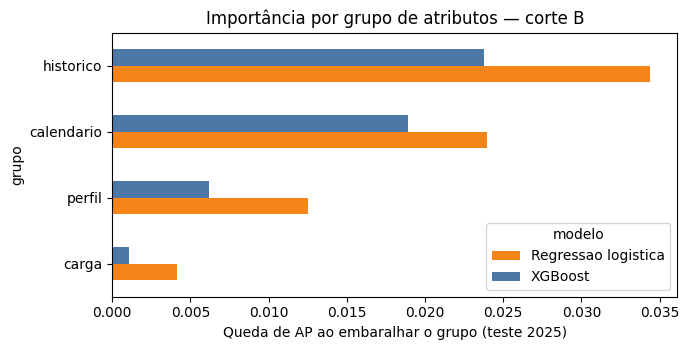

In [11]:
def importancia_grupo(est, Xte, yte, n_rep=20, semente=M.SEMENTE):
    rng = np.random.default_rng(semente)
    base = average_precision_score(yte, est.predict_proba(Xte)[:, 1])
    out = {}
    for g, cols in M.GRUPOS.items():
        quedas = []
        for _ in range(n_rep):
            Xp = Xte.copy()
            perm = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].to_numpy()[perm]
            quedas.append(base - average_precision_score(yte, est.predict_proba(Xp)[:, 1]))
        out[g] = (np.mean(quedas), np.std(quedas))
    return base, out

linhas = []
for c in ["A", "B"]:
    Xtr, ytr, gtr, Xte, yte, gte = separa(c)
    for modelo in [GB, "Regressao logistica"]:
        base, imp = importancia_grupo(MELHORES[c][modelo], Xte, yte)
        for g, (mu, sd) in imp.items():
            linhas.append({"corte": c, "modelo": modelo, "grupo": g, "queda_AP": mu, "dp": sd, "queda_%": 100 * mu / base})
tab_imp = pd.DataFrame(linhas)
display(tab_imp.pivot_table(index="grupo", columns=["corte", "modelo"], values="queda_%").round(1))

fig, ax = plt.subplots(figsize=(7, 3.6))
t = tab_imp[(tab_imp["corte"] == "B")].pivot(index="grupo", columns="modelo", values="queda_AP")
t = t.loc[t[GB].sort_values().index]
t.plot.barh(ax=ax, color=["#F58518", "#4C78A8"][: t.shape[1]])
ax.set_xlabel("Queda de AP ao embaralhar o grupo (teste 2025)")
ax.set_title("Importância por grupo de atributos — corte B")
fig.tight_layout()
fig.savefig(FIG / "m04_importancia_grupos.png", dpi=120)
plt.show()

**Leitura:** embaralhar o **histórico** derruba a AP em 19–31%; o **calendário**, em 15–17%; o **perfil**, em 3–9%; a **carga**, em apenas **0,8–4,8%**. A ordem é a mesma nos dois modelos e nos dois cortes e repete a ablação: o modelo depende do histórico e da exposição, quase nada da carga.

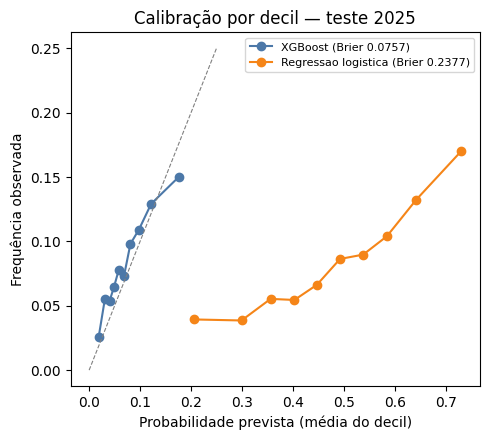

Hiperparâmetros escolhidos:


,A,B,C
Regressao logistica,"{'C': 0.01, 'class_weight': None}","{'C': 1.0, 'class_weight': 'balanced'}","{'C': 0.1, 'class_weight': 'balanced'}"
Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 100}","{'max_features': 0.5, 'min_samples_leaf': 100}","{'max_features': 'sqrt', 'min_samples_leaf': 100}"
XGBoost,"{'max_depth': 2, 'min_child_weight': 20, 'scal...","{'max_depth': 2, 'min_child_weight': 5, 'scale...","{'max_depth': 2, 'min_child_weight': 5, 'scale..."
MLP,{'alpha': 0.1},{'alpha': 0.1},{'alpha': 0.001}


In [12]:
# 6.2 calibração no corte B (o produto é um score relativo, mas a escala importa para a leitura)
Xtr, ytr, gtr, Xte, yte, gte = separa("B")
fig, ax = plt.subplots(figsize=(5, 4.5))
for nome, cor in [(GB, "#4C78A8"), ("Regressao logistica", "#F58518")]:
    s = pd.Series(SCORES["B"][nome])
    dec = pd.qcut(s.rank(method="first"), 10, labels=False)
    prev_p = s.groupby(dec).mean(); obs = pd.Series(yte.to_numpy()).groupby(dec).mean()
    ax.plot(prev_p, obs, marker="o", color=cor, label=f"{nome} (Brier {M.metricas(yte, s)['Brier']:.4f})")
lim = 0.25
ax.plot([0, lim], [0, lim], color="gray", ls="--", lw=0.8)
ax.set_xlabel("Probabilidade prevista (média do decil)"); ax.set_ylabel("Frequência observada")
ax.set_title("Calibração por decil — teste 2025"); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "m05_calibracao.png", dpi=120)
plt.show()
print("Hiperparâmetros escolhidos:")
display(pd.DataFrame({c: {m: str(p) for m, p in PARAMS[c].items()} for c in PARAMS}))

**Leitura:** o XGBoost sem peso está **bem calibrado** (pontos próximos da diagonal), mas seu Brier (0,0757) é quase igual ao de prever a prevalência para todos (≈ 0,077): com discriminação modesta, as probabilidades absolutas acrescentam pouco. A regressão logística com `class_weight="balanced"` **superestima** o risco em 4–5× (efeito do peso) sem mudar a ordenação. Para uso prático, o score deve ser lido como **risco relativo** ou recalibrado. Os hiperparâmetros escolhidos são sempre os mais regularizados da grade.

SHAP médio absoluto por grupo (escala log-odds):


,% do total
calendario,34.700001
historico,33.799999
perfil,18.000000
carga,13.500000


Top 10 atributos (|SHAP| médio):


,|SHAP| médio
jogos_clube_prox_14d,0.3383
log_dias_desde_lesao,0.1503
log_dias_fora_ultima,0.1340
n_lesoes_previas,0.1130
idade,0.0953
pos_ponta,0.0796
titular,0.0695
goleiro,0.0679
minutos_cronica_4sem,0.0643
acwr,0.0611


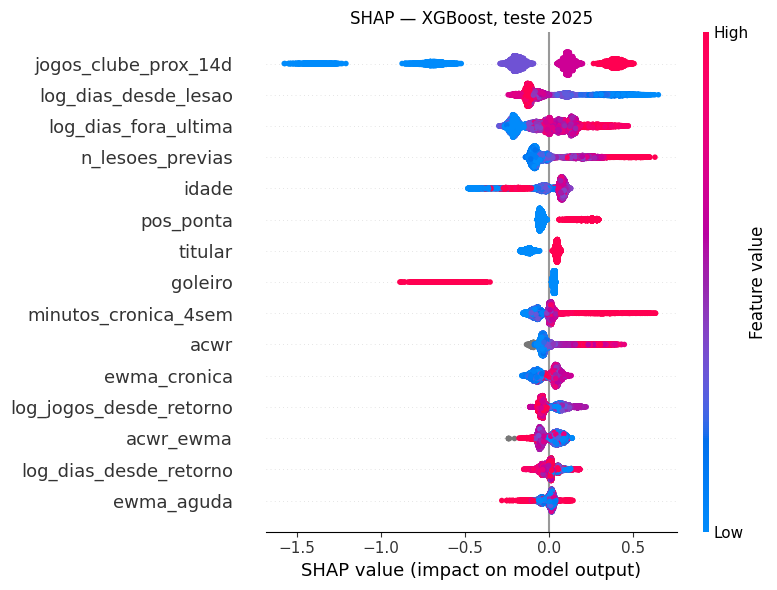

In [13]:
# 6.3 SHAP (só com XGBoost): contribuição de cada atributo para o score no teste do corte B
if M.TEM_XGB:
    import shap
    import xgboost as xgb
    Xtr, ytr, gtr, Xte, yte, gte = separa("B")
    modelo_xgb = MELHORES["B"][GB].named_steps["clf"]
    # TreeSHAP nativo do xgboost (o TreeExplainer do shap 0.49 não lê o base_score do xgboost 3.x);
    # a última coluna é o termo de base, descartada
    contrib = modelo_xgb.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)
    sv = pd.DataFrame(contrib[:, :-1], columns=Xte.columns, index=Xte.index)
    # por grupo: soma das contribuições do grupo em cada linha, depois média do valor absoluto
    por_grupo = pd.Series({g: sv[cols].sum(axis=1).abs().mean() for g, cols in M.GRUPOS.items()})
    print("SHAP médio absoluto por grupo (escala log-odds):")
    display((por_grupo / por_grupo.sum() * 100).round(1).sort_values(ascending=False).rename("% do total").to_frame())
    print("Top 10 atributos (|SHAP| médio):")
    display(sv.abs().mean().sort_values(ascending=False).head(10).round(4).to_frame("|SHAP| médio"))
    shap.summary_plot(sv.to_numpy(), Xte, max_display=15, show=False, plot_size=(8, 6))
    plt.title("SHAP — XGBoost, teste 2025")
    plt.tight_layout()
    plt.savefig(FIG / "m06_shap_beeswarm.png", dpi=120)
    plt.show()
else:
    print("xgboost não instalado: seção SHAP pulada (ver importância por grupo em 6.1).")

**Leitura:** o atributo de maior impacto é `jogos_clube_prox_14d`: sem jogos à frente, o score cai muito (exposição). Em seguida vêm o histórico (recência e gravidade da última lesão, número de lesões) e o perfil (idade; **goleiro** reduz bastante o risco). O grupo de **carga** responde por 13,5% do |SHAP| (carga crônica e ACWR altas empurram o score para cima), bem mais do que os ~1% de queda de AP na permutação. A diferença tem explicação: o SHAP mostra **o que o modelo usa** para mover o score, e a permutação mostra **o que ele precisa** para ordenar bem. A carga é redundante com o calendário e a exposição; quando ela é embaralhada, o modelo compensa com as outras informações. SHAP explica o modelo, não a causa.

## 7. Síntese e critério de sucesso

In [14]:
yB = separa("B")[4]
melhorB = tab_ic.loc["B"].drop(index=[i for i in tab_ic.loc["B"].index if i.startswith(("Dummy", "Regra", "Score"))])["AP"].idxmax()
loB = M.ic(BOOT["B"][melhorB]["AP"])[0]
liftB = tab_mod.loc[("B", melhorB), "lift@10%"]
print(f"Critério 1 (modelo útil, corte B, {melhorB}): IC inferior da AP = {loB:.3f} vs prevalência {yB.mean():.3f}; lift@10% = {liftB:.2f}"
      f" -> {'ATENDIDO' if (loB > yB.mean() and liftB >= 1.5) else 'NÃO atendido'}")
sig = tab_abl.xs("completo", level="atributos").loc[["A", "B"]]
print("Critério 2 (carga acrescenta sinal, cortes A/B):")
display(sig[["AP", "ΔAP carga (IC95)", "carga_significativa"]])
print("->", "ATENDIDO" if sig["carga_significativa"].any() else "NÃO atendido")

Critério 1 (modelo útil, corte B, Regressao logistica): IC inferior da AP = 0.119 vs prevalência 0.084; lift@10% = 2.03 -> ATENDIDO
Critério 2 (carga acrescenta sinal, cortes A/B):


AP            ΔAP carga (IC95) carga_significativa
corte modelo                                                                       
A     XGBoost              0.110886  +0.0006 [-0.0048, +0.0064]               False
      Regressao logistica  0.117763  +0.0017 [-0.0003, +0.0039]               False
B     XGBoost              0.126586  +0.0057 [+0.0006, +0.0119]                True
      Regressao logistica  0.139606  +0.0004 [-0.0036, +0.0043]               False

-> ATENDIDO


### Síntese da modelagem

**Critério 1 — modelo útil: atendido.** No corte B, a regressão logística tem AP de 0,140 [0,119; 0,169] contra prevalência de 0,084 (1,67× o acaso), AUC-ROC de 0,646 e lift@10% de 2,03: os 10% de maior risco concentram o dobro da taxa média de lesões e ~20% de todas as lesões do ano.

**Critério 2 — a carga acrescenta sinal: atendido formalmente, mas frágil.** Só 1 de 4 comparações (XGBoost no corte B) tem IC de ΔAP acima de zero (+0,006). O efeito some no corte C, não aparece no melhor modelo, a carga sozinha fica no nível do acaso, e a importância por permutação é de 1–5%.

**O que se conclui**
1. Dados públicos de partidas permitem **ordenar o risco** de lesão de forma modesta, mas robusta: o sinal se mantém em três cortes temporais, no regime de registro pobre, para clubes e jogadores não vistos e com o alvo alternativo.
2. O sinal vem do **histórico de lesões** (recência, gravidade, número) e do **calendário futuro** (exposição), não da carga de minutos. A regra clássica ACWR ≥ 1,5 não supera o acaso.
3. **Modelos simples bastam:** a regressão logística supera ou empata com XGBoost e Random Forest, e o MLP fica por último. Tratar o desbalanceamento não melhora a ordenação e piora a calibração.

**Limitações**
- O rótulo vem do Transfermarkt, com **deriva de registro** entre anos e entre clubes. As métricas absolutas valem para o regime de 2024–25.
- Não há dados de treino, GPS ou fisiologia. A carga é só de minutos em jogos oficiais.
- AUC ~0,65 e precisão de ~17% no topo: o score serve para **priorização e triagem**, não para diagnóstico individual.
- Os intervalos de confiança não corrigem para comparações múltiplas.